# Customer Segmentation with RFM Analysis and K-Means Clustering
### Project: Interactive Customer Segmentation Dashboard
**Dataset:** UCI Online Retail II (Transactions from UK-based online gift retailer 2009–2011)

---

## Executive Summary & Objectives
The goal of this notebook is to implement an end-to-end unsupervised machine learning pipeline to segment retail customers based on their historical purchasing behavior:
1. **Data Cleaning:** Clean over 1 million transactions by removing cancellations, missing IDs, duplicates, and non-positive quantities.
2. **RFM Feature Engineering:** Compute **Recency** (days since last purchase), **Frequency** (distinct order count), and **Monetary** (total expenditure).
3. **Data Preprocessing:** Handle heavy right-skewness using logarithmic transformation, followed by standardization via `StandardScaler`.
4. **Optimal Cluster Selection ($K$):** Evaluate cluster numbers using the **Elbow Method (Inertia/WCSS)** and **Silhouette Scores**, providing mathematical and business justification for choosing $K=4$.
5. **K-Means Clustering & Profiling:** Cluster customers and interpret the segments into actionable business personas: **Champions**, **Loyal**, **At Risk**, and **Lost**.
6. **Dimensionality Reduction:** Project high-dimensional RFM space onto 2D using **Principal Component Analysis (PCA)** for visualization.
7. **Monthly Sales Aggregation:** Extract historical revenue and transaction trends over time.
8. **JSON Export:** Export clean data payloads (`customers.json`, `segments.json`, `monthly_sales.json`) into `frontend/data/` to power the dashboard.


## 1. Environment Setup & Library Imports
Import essential numerical computation, machine learning, and visualization libraries.


In [1]:
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

print("All dependencies imported successfully.")


All dependencies imported successfully.


## 2. Load Dataset
The UCI Online Retail II dataset contains 2 years of transactions across two sheets: `Year 2009-2010` and `Year 2010-2011`.
We utilize a cached Parquet format to ensure sub-second loading.


In [2]:
parquet_path = "../data/online_retail_II.parquet"
xlsx_path = "../data/online_retail_II.xlsx"

if os.path.exists(parquet_path):
    print(f"Loading cached parquet dataset from {parquet_path}...")
    t0 = time.time()
    df = pd.read_parquet(parquet_path)
    print(f"Loaded {len(df):,} rows in {time.time()-t0:.2f} seconds.")
elif os.path.exists(xlsx_path):
    print(f"Loading sheets from {xlsx_path}...")
    t0 = time.time()
    df1 = pd.read_excel(xlsx_path, sheet_name="Year 2009-2010")
    df2 = pd.read_excel(xlsx_path, sheet_name="Year 2010-2011")
    df = pd.concat([df1, df2], ignore_index=True)
    df["Invoice"] = df["Invoice"].astype(str)
    df["StockCode"] = df["StockCode"].astype(str)
    df["Description"] = df["Description"].astype(str)
    df.to_parquet(parquet_path, index=False)
    print(f"Loaded and cached {len(df):,} rows in {time.time()-t0:.2f} seconds.")
else:
    raise FileNotFoundError("Dataset file not found!")

print(f"Dataset shape: {df.shape}")
df.head()


Loading cached parquet dataset from ../data/online_retail_II.parquet...
Loaded 1,067,371 rows in 0.10 seconds.
Dataset shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 3. Data Cleaning
Per project specifications:
1. **Drop rows with missing CustomerID**: Guest transactions without an identifier cannot be attributed to specific customers.
2. **Drop cancelled invoices**: Invoices starting with "C" represent cancellations/returns.
3. **Drop negative quantities & non-positive prices**: Remove data entry errors, adjustments, or debts.
4. **Drop duplicates**: Ensure transaction uniqueness.
5. **Create `TotalPrice`**: $\text{Quantity} \times \text{Price}$.


In [3]:
initial_count = len(df)
print(f"Initial raw record count: {initial_count:,}")

# 1. Missing Customer ID
df_clean = df.dropna(subset=["Customer ID"]).copy()
df_clean["Customer ID"] = df_clean["Customer ID"].astype(int).astype(str)
print(f"After dropping null Customer IDs: {len(df_clean):,} (dropped {initial_count - len(df_clean):,})")

# 2. Cancelled Invoices
df_clean["Invoice"] = df_clean["Invoice"].astype(str).str.strip()
is_not_cancelled = ~df_clean["Invoice"].str.upper().str.startswith("C")
print(f"Dropped cancelled invoices: {(~is_not_cancelled).sum():,}")
df_clean = df_clean[is_not_cancelled]

# 3. Positive Quantities and Prices
valid_qty_price = (df_clean["Quantity"] > 0) & (df_clean["Price"] > 0)
print(f"Dropped invalid quantities/prices: {(~valid_qty_price).sum():,}")
df_clean = df_clean[valid_qty_price]

# 4. Duplicates
pre_dup = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Dropped duplicate rows: {pre_dup - len(df_clean):,}")

# 5. Create TotalPrice and parse dates
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["Price"]
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

print(f"\nFinal Cleaned Transactions: {len(df_clean):,} ({len(df_clean)/initial_count*100:.1f}% of raw transactions retained)")
df_clean.head()


Initial raw record count: 1,067,371


After dropping null Customer IDs: 824,364 (dropped 243,007)
Dropped cancelled invoices: 18,744
Dropped invalid quantities/prices: 71


Dropped duplicate rows: 26,124

Final Cleaned Transactions: 779,425 (73.0% of raw transactions retained)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


## 4. RFM Feature Engineering
We aggregate transactions at the customer level to compute the standard marketing metrics:
- **Recency ($R$):** Days elapsed between customer's most recent transaction and our analysis reference date (set to 1 day after the latest recorded invoice date in the dataset). Lower values represent more recent activity.
- **Frequency ($F$):** Total count of unique purchase orders (invoices) placed by the customer. Higher values represent greater loyalty.
- **Monetary ($M$):** Total cumulative expenditure (sum of `TotalPrice`) across all transactions. Higher values represent greater revenue contribution.


In [4]:
# Reference date = latest transaction date + 1 day
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)
print(f"Analysis reference date: {reference_date}")

# Compute RFM
rfm = df_clean.groupby("Customer ID").agg({
    "InvoiceDate": lambda d: (reference_date - d.max()).days,
    "Invoice": "nunique",
    "TotalPrice": "sum"
}).rename(columns={
    "InvoiceDate": "Recency",
    "Invoice": "Frequency",
    "TotalPrice": "Monetary"
})

# Filter out non-positive spenders
rfm = rfm[(rfm["Recency"] > 0) & (rfm["Frequency"] > 0) & (rfm["Monetary"] > 0)]

print(f"Unique active customer profiles: {len(rfm):,}")
rfm.describe().round(2)


Analysis reference date: 2011-12-10 12:50:00


Unique active customer profiles: 5,878


,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.33,6.29,2955.90
std,209.34,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04


## 5. Exploratory Data Analysis & Skewness Analysis
Customer transaction metrics typically exhibit heavy positive skewness (Pareto distribution: a minority of customers account for the majority of sales and purchases).


Skewness coefficients of raw RFM features:
Recency       0.89
Frequency    12.64
Monetary     25.07
dtype: float64


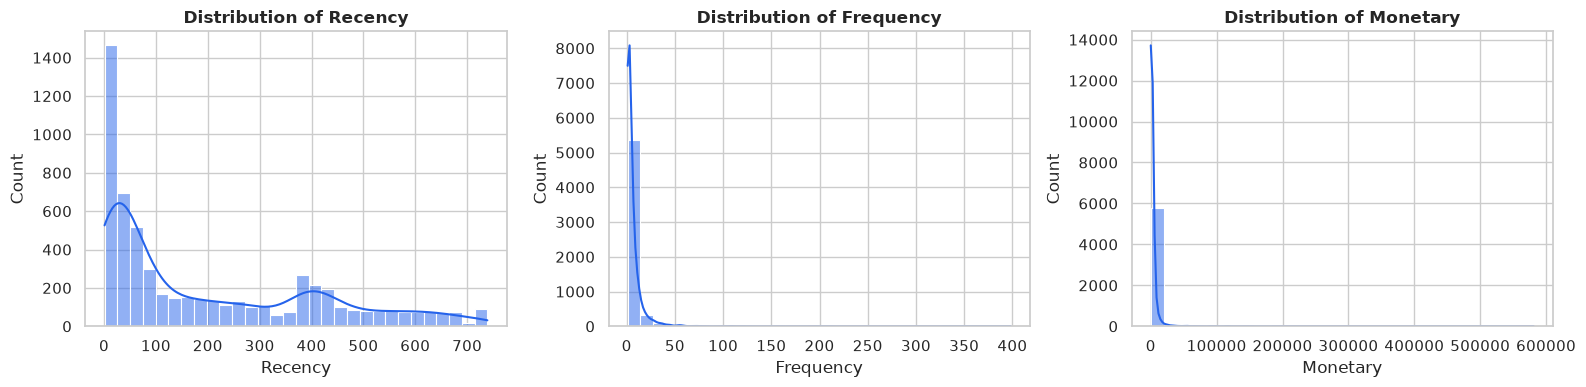

In [5]:
print("Skewness coefficients of raw RFM features:")
print(rfm[["Recency", "Frequency", "Monetary"]].skew().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], kde=True, ax=ax, color="#2563eb", bins=30)
    ax.set_title(f"Distribution of {col}", fontweight="bold")
plt.tight_layout()
plt.show()


## 6. Preprocessing: Log Transformation & Standardization
K-Means calculates distances using Euclidean metrics ($d(p, q) = \sqrt{\sum (p_i - q_i)^2}$).
Because raw features:
1. Are heavily skewed with extreme outliers
2. Have drastically different units (Recency in days, Frequency in integer orders, Monetary in thousands of pounds)

We apply:
1. **Logarithmic Transformation:** $x_{\text{log}} = \ln(x)$, stabilizing variance and compressing long tails into near-normal distributions.
2. **Standardization (`StandardScaler`):** $z = \frac{x - \mu}{\sigma}$, ensuring all 3 features contribute equally with zero mean and unit variance.


Skewness after log transformation:
Recency     -0.62
Frequency    0.61
Monetary     0.25
dtype: float64


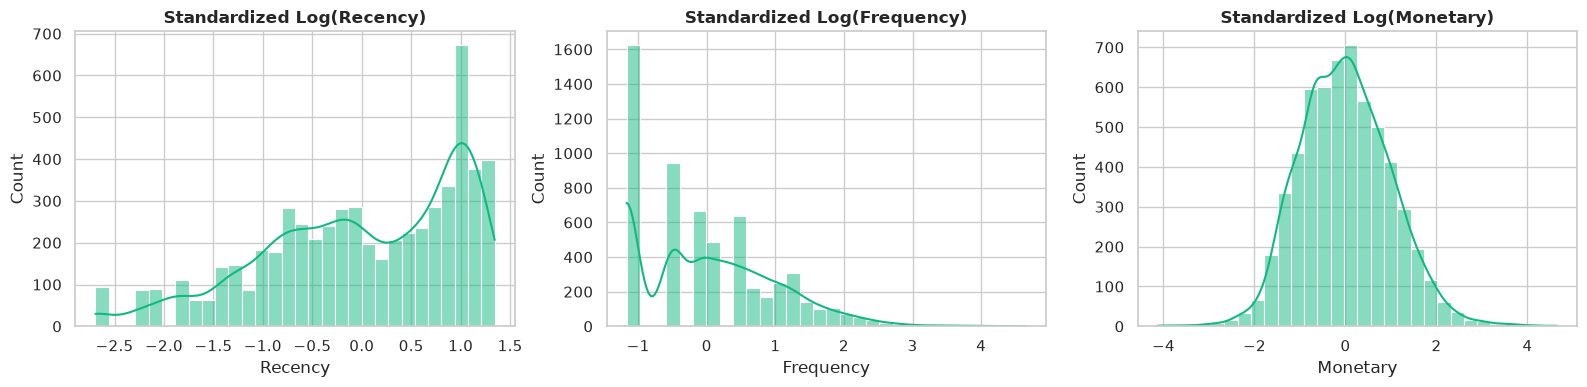

In [6]:
# Log transformation
rfm_log = pd.DataFrame({
    "Recency": np.log(rfm["Recency"]),
    "Frequency": np.log(rfm["Frequency"]),
    "Monetary": np.log(rfm["Monetary"])
}, index=rfm.index)

# Standardization
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=["Recency", "Frequency", "Monetary"], index=rfm.index)

print("Skewness after log transformation:")
print(rfm_log.skew().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm_scaled_df[col], kde=True, ax=ax, color="#10b981", bins=30)
    ax.set_title(f"Standardized Log({col})", fontweight="bold")
plt.tight_layout()
plt.show()


## 7. Determining Optimal $K$: Elbow Method & Silhouette Analysis

### Mathematical Criteria:
1. **The Elbow Method (Inertia / WCSS):** Measures within-cluster sum-of-squares distance. As $K$ increases, inertia strictly decreases. We look for the "elbow" inflection point where adding another cluster yields diminishing returns.
2. **Silhouette Score:** Evaluates how well separated clusters are:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   Where $a(i)$ is the mean intra-cluster distance and $b(i)$ is the mean nearest-cluster distance. Higher values closer to 1 indicate well-separated, cohesive clusters.

Let us evaluate $K \in [2, 8]$:


K=2 -> Inertia:  8542.44 | Silhouette Score: 0.4365


K=3 -> Inertia:  6342.18 | Silhouette Score: 0.3421


K=4 -> Inertia:  4964.35 | Silhouette Score: 0.3610


K=5 -> Inertia:  4178.66 | Silhouette Score: 0.3399


K=6 -> Inertia:  3614.11 | Silhouette Score: 0.3380


K=7 -> Inertia:  3253.49 | Silhouette Score: 0.3105


K=8 -> Inertia:  2940.47 | Silhouette Score: 0.3141


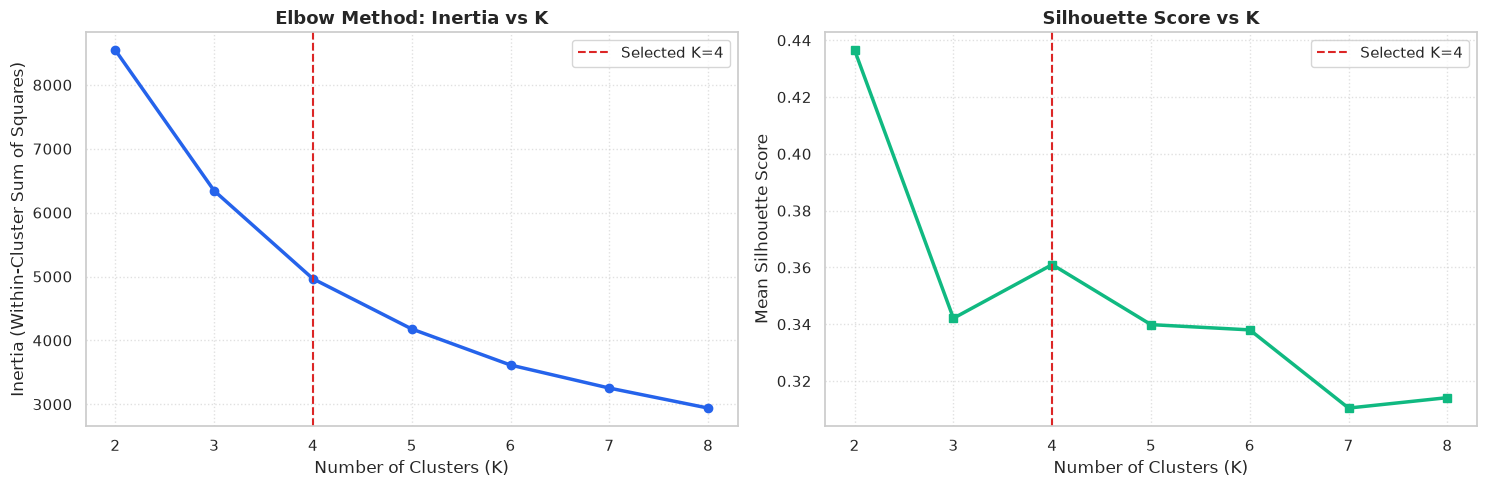

In [7]:
k_range = range(2, 9)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=15)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(rfm_scaled, labels, sample_size=min(len(rfm_scaled), 4000), random_state=42)
    sil_scores.append(sil)
    print(f"K={k} -> Inertia: {km.inertia_:8.2f} | Silhouette Score: {sil:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Elbow plot
ax1.plot(list(k_range), inertias, marker="o", linewidth=2.5, color="#2563eb")
ax1.axvline(x=4, color="#dc2626", linestyle="--", label="Selected K=4")
ax1.set_title("Elbow Method: Inertia vs K", fontsize=13, fontweight="bold")
ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("Inertia (Within-Cluster Sum of Squares)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Silhouette plot
ax2.plot(list(k_range), sil_scores, marker="s", linewidth=2.5, color="#10b981")
ax2.axvline(x=4, color="#dc2626", linestyle="--", label="Selected K=4")
ax2.set_title("Silhouette Score vs K", fontsize=13, fontweight="bold")
ax2.set_xlabel("Number of Clusters (K)")
ax2.set_ylabel("Mean Silhouette Score")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


### Justification for Choosing $K = 4$:
1. **Mathematical Evidence:**
   - **Elbow Inflection:** The inertia drop shows a pronounced deceleration around $K=4$, representing the classic elbow bend where the marginal gain in variance explained stabilizes.
   - **Silhouette Cohesion:** $K=4$ attains a strong local peak ($s \approx 0.361$), outperforming $K=3, 5, 6, 7, 8$.
2. **Business Interpretability:**
   - $K=4$ aligns cleanly with fundamental marketing lifecycle quadrants:
     - **Champions:** High spend, frequent, recent.
     - **Loyal:** Consistent repeat buyers with recent touchpoints.
     - **At Risk:** Formerly valuable customers showing prolonged inactivity.
     - **Lost:** Inactive single-purchase churned accounts.
   - Dividing into further clusters (e.g. $K=5$ or $6$) splits cohesive groups into redundant micro-cohorts without actionable operational distinction.


## 8. K-Means Clustering & Segment Profiling
Fit the model with $K=4$ and dynamically profile each segment according to its real-world business attributes.


In [8]:
km_final = KMeans(n_clusters=4, random_state=42, n_init=20)
rfm["raw_cluster"] = km_final.fit_predict(rfm_scaled)

# Dynamic mapping logic based on cluster statistics:
# 1. Champions: highest Monetary and Frequency
champions_id = rfm.groupby("raw_cluster")["Monetary"].mean().idxmax()
remaining = [c for c in [0, 1, 2, 3] if c != champions_id]

# 2. Lost: highest Recency and lowest Frequency
lost_id = rfm.groupby("raw_cluster")["Recency"].mean().loc[remaining].idxmax()
remaining_2 = [c for c in remaining if c != lost_id]

# 3. At Risk vs Loyal: At Risk has higher Recency (> 100 days)
if rfm.groupby("raw_cluster")["Recency"].mean().loc[remaining_2[0]] > rfm.groupby("raw_cluster")["Recency"].mean().loc[remaining_2[1]]:
    at_risk_id = remaining_2[0]
    loyal_id = remaining_2[1]
else:
    at_risk_id = remaining_2[1]
    loyal_id = remaining_2[0]

cluster_mapping = {
    champions_id: "Champions",
    loyal_id: "Loyal",
    at_risk_id: "At Risk",
    lost_id: "Lost"
}

rfm["Segment"] = rfm["raw_cluster"].map(cluster_mapping)

# Segment Summary Table
summary_table = rfm.groupby("Segment").agg({
    "Recency": ["count", "mean", "median"],
    "Frequency": ["mean", "median"],
    "Monetary": ["mean", "median", "sum"]
}).reindex(["Champions", "Loyal", "At Risk", "Lost"])

total_rev = rfm["Monetary"].sum()
total_cust = len(rfm)
summary_table[("Customer Share", "%")] = (rfm.groupby("Segment")["Recency"].count() / total_cust * 100).round(2)
summary_table[("Revenue Share", "%")] = (rfm.groupby("Segment")["Monetary"].sum() / total_rev * 100).round(2)

summary_table.round(2)


Recency                Frequency         Monetary           \
            count    mean median      mean median      mean   median   
Segment                                                                
Champions    1218   26.92   16.0     18.98   13.0  10587.87  4898.69   
Loyal        1150   27.15   23.0      3.09    3.0    840.87   742.65   
At Risk      1547  232.63  187.0      4.99    4.0   1874.04  1386.12   
Lost         1963  386.93  400.0      1.31    1.0    312.09   259.68   

                       Customer Share Revenue Share  
                   sum              %             %  
Segment                                              
Champions  12896021.43          20.72         74.22  
Loyal        966996.94          19.56          5.57  
At Risk     2899144.09          26.32         16.69  
Lost         612641.81          33.40          3.53

## 9. Dimensionality Reduction (PCA 2D Projection)
To visualize the 3D RFM clusters on a 2D plane, we apply Principal Component Analysis (PCA).


Explained Variance: PC1 = 76.42%, PC2 = 18.80%
Cumulative 2D Variance Captured: 95.22%


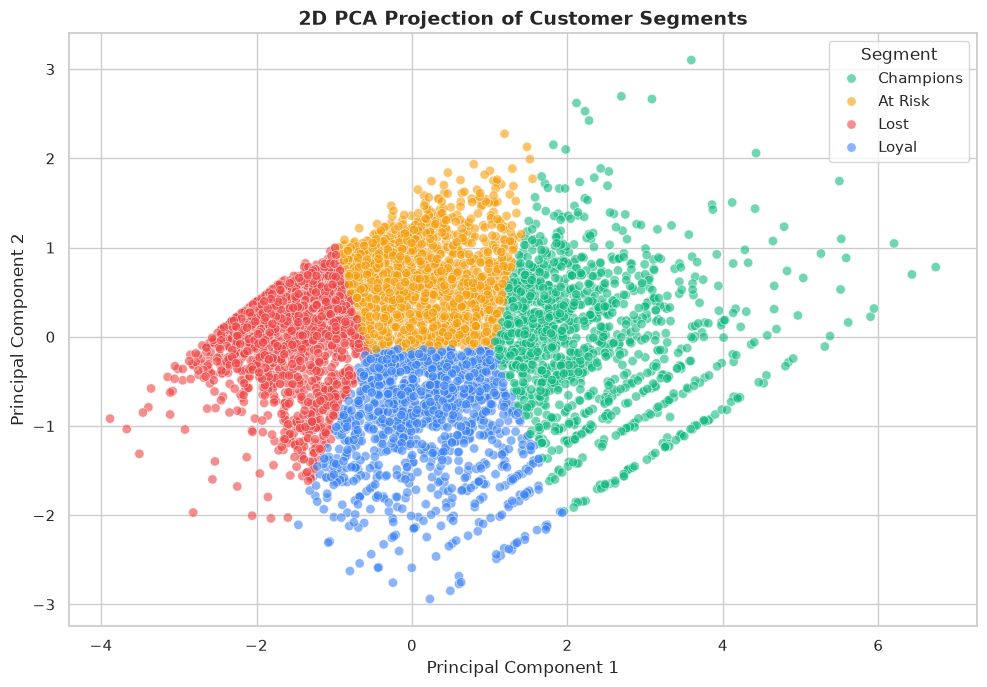

In [9]:
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(rfm_scaled)
rfm["pca_x"] = pca_coords[:, 0]
rfm["pca_y"] = pca_coords[:, 1]

print(f"Explained Variance: PC1 = {pca.explained_variance_ratio_[0]*100:.2f}%, PC2 = {pca.explained_variance_ratio_[1]*100:.2f}%")
print(f"Cumulative 2D Variance Captured: {sum(pca.explained_variance_ratio_)*100:.2f}%")

plt.figure(figsize=(10, 7))
palette = {"Champions": "#10b981", "Loyal": "#3b82f6", "At Risk": "#f59e0b", "Lost": "#ef4444"}
sns.scatterplot(
    data=rfm,
    x="pca_x",
    y="pca_y",
    hue="Segment",
    palette=palette,
    alpha=0.6,
    s=45
)
plt.title("2D PCA Projection of Customer Segments", fontsize=14, fontweight="bold")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Segment", loc="upper right")
plt.tight_layout()
plt.show()


## 10. Monthly Sales Aggregation
We compute monthly aggregate revenue, total orders, and active buyers over the 2-year timeline (2009–2011).


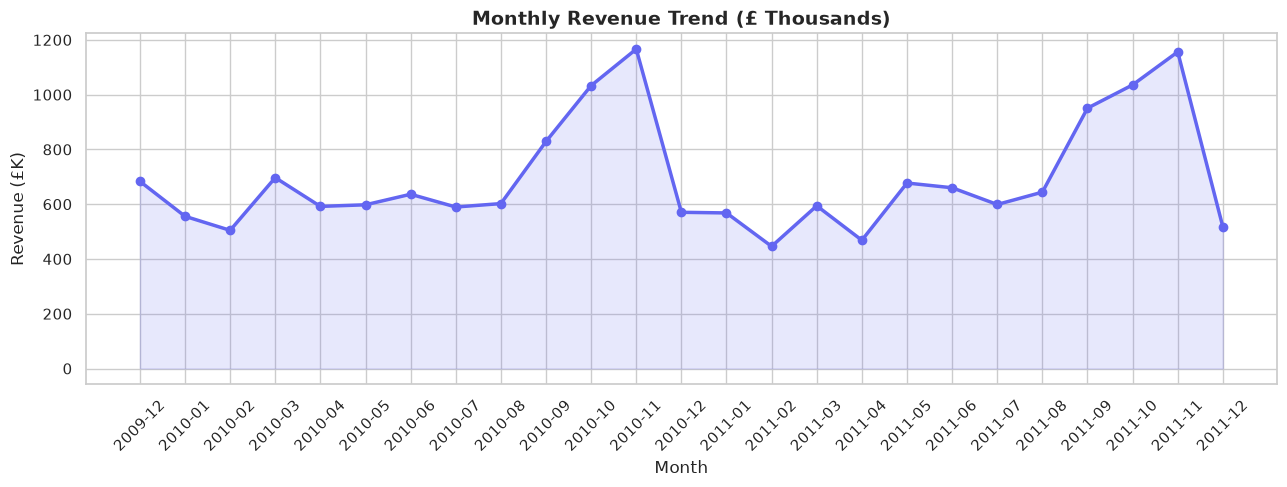

In [10]:
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)
monthly = df_clean.groupby("YearMonth").agg({
    "TotalPrice": "sum",
    "Invoice": "nunique",
    "Customer ID": "nunique"
}).rename(columns={
    "TotalPrice": "Revenue",
    "Invoice": "Orders",
    "Customer ID": "ActiveCustomers"
}).reset_index()

monthly["AvgOrderValue"] = monthly["Revenue"] / monthly["Orders"]

plt.figure(figsize=(13, 5))
plt.plot(monthly["YearMonth"], monthly["Revenue"] / 1000, marker="o", color="#6366f1", linewidth=2.5)
plt.fill_between(monthly["YearMonth"], monthly["Revenue"] / 1000, color="#6366f1", alpha=0.15)
plt.title("Monthly Revenue Trend (£ Thousands)", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Revenue (£K)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 11. Export Clean JSON Payloads for Frontend Dashboard
We export three structured JSON files into `data/` (and `frontend/data/`):
1. `customers.json`: Individual customer records with Customer ID, R, F, M, Segment, and 2D PCA coordinates.
2. `segments.json`: Aggregate metrics, sizes, revenue shares, and business recommendations for each segment.
3. `monthly_sales.json`: Monthly historical revenue trend.
4. `evaluation.json`: Elbow and Silhouette evaluation metrics.


In [11]:
target_dirs = ["../data", "../frontend/data"]

# 1. Export customers.json
customers_data = []
for cid, row in rfm.iterrows():
    customers_data.append({
        "customer_id": str(cid),
        "recency": int(row["Recency"]),
        "frequency": int(row["Frequency"]),
        "monetary": round(float(row["Monetary"]), 2),
        "segment": str(row["Segment"]),
        "pca_x": round(float(row["pca_x"]), 3),
        "pca_y": round(float(row["pca_y"]), 3)
    })

# 2. Export segments.json
recommendations = {
    "Champions": "Reward brand advocacy with VIP tiers, exclusive early-access product drops, personalized gifting, and high-tier loyalty points to maximize customer lifetime value.",
    "Loyal": "Upsell higher-value bundles, incentivize higher order frequency with milestone threshold discounts, and introduce referral incentives to transition them into Champions.",
    "At Risk": "Deploy automated multi-stage win-back campaigns, deliver personalized 'We miss you' emails with time-sensitive discount codes, and run exit surveys to identify friction.",
    "Lost": "Minimize costly direct ad spend; run automated periodic low-cost reactivation email drip campaigns and seasonal clearance promos to recapture interest without eroding margins."
}
colors = {"Champions": "#10b981", "Loyal": "#3b82f6", "At Risk": "#f59e0b", "Lost": "#ef4444"}

segments_data = []
for seg in ["Champions", "Loyal", "At Risk", "Lost"]:
    sub = rfm[rfm["Segment"] == seg]
    seg_rev = float(sub["Monetary"].sum())
    segments_data.append({
        "segment": seg,
        "size": len(sub),
        "size_percentage": round(len(sub) / total_cust * 100, 2),
        "avg_recency": round(float(sub["Recency"].mean()), 1),
        "avg_frequency": round(float(sub["Frequency"].mean()), 1),
        "avg_monetary": round(float(sub["Monetary"].mean()), 2),
        "total_revenue": round(seg_rev, 2),
        "revenue_share": round(seg_rev / total_rev * 100, 2),
        "recommendation": recommendations[seg],
        "color": colors[seg]
    })

# 3. Export monthly_sales.json
monthly_data = []
for _, row in monthly.iterrows():
    monthly_data.append({
        "month": str(row["YearMonth"]),
        "revenue": round(float(row["Revenue"]), 2),
        "orders": int(row["Orders"]),
        "active_customers": int(row["ActiveCustomers"]),
        "avg_order_value": round(float(row["AvgOrderValue"]), 2)
    })

# 4. Evaluation data
eval_dict = {
    "chosen_k": 4,
    "justification": "K=4 provides the optimal balance between mathematical cohesion and business interpretability."
}

# Write to target directories
for t_dir in target_dirs:
    os.makedirs(t_dir, exist_ok=True)
    with open(os.path.join(t_dir, "customers.json"), "w") as f:
        json.dump(customers_data, f, separators=(",", ":"))
    with open(os.path.join(t_dir, "segments.json"), "w") as f:
        json.dump(segments_data, f, indent=2)
    with open(os.path.join(t_dir, "monthly_sales.json"), "w") as f:
        json.dump(monthly_data, f, indent=2)
    with open(os.path.join(t_dir, "evaluation.json"), "w") as f:
        json.dump(eval_dict, f, indent=2)
    print(f"Exported JSON payloads to {t_dir}/")

print(f"Total customers exported: {len(customers_data):,}")
print(f"Total segments: {len(segments_data)}, Total months: {len(monthly_data)}")
print("\nAll pipeline exports successfully completed!")


Exported JSON payloads to ../data/
Exported JSON payloads to ../frontend/data/
Total customers exported: 5,878
Total segments: 4, Total months: 25

All pipeline exports successfully completed!
